# INITIAL FILTERING

## Imports

In [1]:
import json
import glob
import zipfile
from pathlib import Path
from scipy import ndimage

import numpy as np
import pandas as pd
import rasterio
import requests
import rioxarray
import earthaccess

RAW = Path("../data/raw")
OUT = Path("../data/processed")
FRONT = Path("../public/data")
for d in (RAW / "worldclim", RAW / "modis_lc", OUT, FRONT):
    d.mkdir(parents=True, exist_ok=True)

RES = 0.5
NCOLS = int(360 / RES)            # 720

C:\Users\Rashidat\miniforge3\envs\spaceapps\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data download (skips files already present)

In [2]:
def download(url, dest):
    dest = Path(dest)
    if dest.exists():
        print(f"✓ already have {dest.name}")
        return dest
    print(f"↓ downloading {dest.name} ...")
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    return dest

# WorldClim 2.1 bioclim, 10 arc-minutes
WC_URL = "https://geodata.ucdavis.edu/climate/worldclim/2_1/base/wc2.1_10m_bio.zip"
wc_zip = download(WC_URL, RAW / "worldclim" / "wc2.1_10m_bio.zip")
wc_bio1 = RAW / "worldclim" / "wc2.1_10m_bio_1.tif"
if not wc_bio1.exists():
    with zipfile.ZipFile(wc_zip) as z:
        z.extractall(RAW / "worldclim")
    print("✓ unzipped WorldClim")

# MODIS MCD12C1 land cover (NASA Earthdata login needed)
existing_lc = sorted((RAW / "modis_lc").glob("MCD12C1*.hdf"))
if existing_lc:
    lc_path = existing_lc[-1]
    print(f"✓ already have {lc_path.name}")
else:
    earthaccess.login(persist=True)
    res = earthaccess.search_data(short_name="MCD12C1", version="061",
                                  temporal=("2022-01-01", "2022-12-31"))
    lc_path = Path(earthaccess.download(res[:1], str(RAW / "modis_lc"))[0])
    print(f"✓ downloaded {lc_path.name}")

✓ already have wc2.1_10m_bio.zip
✓ already have MCD12C1.A2022001.061.2023244164746.hdf


## Stable cell ID

In [3]:
def cell_id(lat, lon):
    lat = np.asarray(lat); lon = np.asarray(lon)
    row = ((90 - lat) // RES).astype(int)       # 0 = northernmost row
    col = ((lon + 180) // RES).astype(int)      # 0 = lon -180
    return row * NCOLS + col

## Base grid: WorldClim temperature (defines land cells)

In [4]:
t = rioxarray.open_rasterio(f"{RAW}/worldclim/wc2.1_10m_bio_1.tif", masked=True).squeeze()
t05 = t.coarsen(x=3, y=3, boundary="trim").mean().rio.write_crs(4326)

## MODIS land cover (% per IGBP class)

In [20]:
with rasterio.open(lc_path) as src:
    sds = next(s for s in src.subdatasets if s.endswith("Land_Cover_Type_1_Percent"))

pct = rioxarray.open_rasterio(sds, masked=True).squeeze()
print("Land cover bands:", dict(pct.sizes))     # expect band: 17 → band = class + 1

def igbp(c):
    """Percent of IGBP class c per 0.5° cell, aligned to t05."""
    return (pct.sel(band=c + 1).coarsen(x=10, y=10, boundary="trim").mean().rio.write_crs(4326).rio.reproject_match(t05))

layers = {
    "water_pct":  igbp(0),
    "forest_pct": sum(igbp(c) for c in range(1, 6)),
    "urban_pct":  igbp(13),
    "snow_pct":   igbp(15),     # info only
    "barren_pct": igbp(16),     # info only
}

C:\Users\Rashidat\miniforge3\envs\spaceapps\Lib\site-packages\rasterio\__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Land cover bands: {'band': 17, 'y': 3600, 'x': 7200}


In [21]:
### ETOPO 2022 bedrock: slope, ruggedness, elevation stats per 0.5° cell
ETOPO_DIR = RAW / "etopo"
ETOPO_DIR.mkdir(parents=True, exist_ok=True)
etopo_paths = sorted(ETOPO_DIR.glob("ETOPO_2022_v1_15s_*_bed.tif"))
assert etopo_paths, "Drop your ETOPO_2022_v1_15s_*.tif tiles into data/raw/etopo/"

def compute_etopo_features(tif_path, target_da, res_deg=0.5, px_per_cell=120):
    """Slope (deg), TRI (m), elevation stats aggregated to 0.5° cells.
    Returns dict of 2D arrays aligned to target_da (t05) via reproject_match.
    """
    with rasterio.open(tif_path) as src:
        dem = src.read(1).astype("float64")
        if src.nodata is not None:
            dem[dem == src.nodata] = np.nan
        crs = src.crs
        tr = src.transform
        epsg = crs.to_epsg()
        if epsg not in (4326, 9518):
            raise ValueError(f"Unexpected CRS: {crs} (EPSG:{epsg})")

        # --- convert degree pixel size to metres at this tile's latitude ---
        lat_c = (src.bounds.bottom + src.bounds.top) / 2
        dx_m = abs(tr.a) * 111320 * np.cos(np.radians(lat_c))
        dy_m = abs(tr.e) * 110574

    # --- slope via Horn (3x3) ---
    kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]) / (8 * dx_m)
    ky = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]]) / (8 * dy_m)
    dem_f = np.where(np.isnan(dem), np.nanmean(dem), dem)
    dzdx = ndimage.convolve(dem_f, kx, mode="nearest")
    dzdy = ndimage.convolve(dem_f, ky, mode="nearest")
    slope = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
    slope[np.isnan(dem)] = np.nan

    tri = np.zeros_like(dem)
    cnt = np.zeros_like(dem)
    for dy, dx in [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]:
        nb = np.roll(np.roll(dem, dy, 0), dx, 1)
        d = np.abs(dem - nb)
        v = ~np.isnan(d)
        tri[v] += d[v]; cnt[v] += 1
    tri = np.where(cnt > 0, tri / np.maximum(cnt, 1), np.nan)

    def block_stat(arr, func):
        h, w = arr.shape
        hb, wb = h // px_per_cell, w // px_per_cell
        a = arr[:hb*px_per_cell, :wb*px_per_cell].reshape(hb, px_per_cell, wb, px_per_cell)
        with np.errstate(all="ignore"):
            return func(a, axis=(1, 3))

    # ETOPO is 15" = 1/240°, a 0.5° block = 120 px exactly
    blocks = {
        "slope_mean": block_stat(slope, np.nanmean),
        "slope_p90":  block_stat(slope, lambda a, axis: np.nanpercentile(a, 90, axis=axis)),
        "rough_p90":  block_stat(tri,   lambda a, axis: np.nanpercentile(a, 90, axis=axis)),
        "elev_min":   block_stat(dem,   np.nanmin),
        "elev_max":   block_stat(dem,   np.nanmax),
    }
    blocks["elev_range"] = blocks["elev_max"] - blocks["elev_min"]

    with rasterio.open(tif_path) as src:
        top, left = src.bounds.top, src.bounds.left
    block_tr = rasterio.transform.from_origin(left, top, res_deg, res_deg)
    out = {}
    for name, arr in blocks.items():
        da = rioxarray.open_rasterio  # placeholder
        import xarray as xr
        x = left + res_deg * (np.arange(arr.shape[1]) + 0.5)
        y = top  - res_deg * (np.arange(arr.shape[0]) + 0.5)
        da = xr.DataArray(arr, dims=("y", "x"),
                          coords={"y": y, "x": x}).rio.write_crs(4326)
        # trim to whole globe if needed, then match to t05
        if da.x.max() > 180: da = da.assign_coords(x=(((da.x + 180) % 360) - 180)).sortby("x")
        out[name] = da.rio.reproject_match(target_da)
    return out

etopo_layers = {}
for p in etopo_paths:
    tile_feats = compute_etopo_features(p, t05)
    for k, v in tile_feats.items():
        if k not in etopo_layers:
            etopo_layers[k] = v
        else:
            etopo_layers[k] = etopo_layers[k].fillna(v)

print("ETOPO layers:", {k: dict(v.sizes) for k, v in etopo_layers.items()})

ETOPO layers: {'slope_mean': {'y': 360, 'x': 720}, 'slope_p90': {'y': 360, 'x': 720}, 'rough_p90': {'y': 360, 'x': 720}, 'elev_min': {'y': 360, 'x': 720}, 'elev_max': {'y': 360, 'x': 720}, 'elev_range': {'y': 360, 'x': 720}}


## Master table: one row per land cell

In [22]:
lon2d, lat2d = np.meshgrid(t05.x.values, t05.y.values)
cells = pd.DataFrame({"lat": lat2d.ravel(), "lon": lon2d.ravel(),
                      "temp": t05.values.ravel()})

for name, da in {**layers, **etopo_layers}.items():
    cells[name] = da.values.ravel()

cells = cells.dropna(subset=["temp"]).reset_index(drop=True)
cells.insert(0, "cell_id", cell_id(cells.lat, cells.lon))
cells["temp_p"] = cells["temp"].rank(pct=True)
print(f"Land cells: {len(cells):,}")

expected = {"forest_pct", "urban_pct", "water_pct", "slope_p90", "rough_p90"}
missing = expected - set(cells.columns)
assert not missing, f"master table is missing {missing}; got {sorted(cells.columns)}"

Land cells: 95,447


## Filter registry

In [23]:
FILTERS = {
    "forest": lambda df: df.forest_pct.fillna(0) <= 10,
    "urban":  lambda df: df.urban_pct.fillna(0)  <= 2,
    "water":  lambda df: df.water_pct.fillna(0)  <= 25,
    # terrain — only apply where ETOPO covers the cell
    "slope":  lambda df: df.slope_p90.fillna(0)  <= 15,
    "rough":  lambda df: df.rough_p90.fillna(0)  <= 50,
    # add later, e.g.: "protected": lambda df: df.protected_share.fillna(0) < 0.5,
}

def apply_filters(df):
    pass_cols = []
    for name, rule in FILTERS.items():
        col = f"pass_{name}"
        df[col] = rule(df)
        pass_cols.append(col)
    df["passes_all"] = df[pass_cols].all(axis=1)
    df["excluded_by"] = df[pass_cols].apply(
        lambda r: ", ".join(c[5:] for c in pass_cols if not r[c]), axis=1)
    return df

cells = apply_filters(cells)

## Funnel (for the pitch)

In [24]:
print("\nFunnel:")
remaining = np.ones(len(cells), dtype=bool)
print(f"  start     : {remaining.sum():,} cells")
for name in FILTERS:
    remaining &= cells[f"pass_{name}"].values
    print(f"  after {name:<6}: {remaining.sum():,} cells")


Funnel:
  start     : 95,447 cells
  after forest: 77,604 cells
  after urban : 75,129 cells
  after water : 62,626 cells
  after slope : 62,626 cells
  after rough : 62,626 cells


## Validation: do known analogs survive?

In [25]:
analogs = pd.DataFrame([
    ("Atacama Desert",        -24.50,  -69.25),
    ("Antarctic Dry Valleys", -77.50,  162.00),
    ("Haughton Crater",        75.38,  -89.67),
    ("Mauna Kea",              19.82, -155.47),
    ("Black Point Lava Flow",  35.70, -111.40),
    ("Rio Tinto",              37.70,   -6.60),
    ("Teide",                  28.27,  -16.64),
], columns=["name", "lat", "lon"])
analogs["cell_id"] = cell_id(analogs.lat, analogs.lon)

check = analogs.merge(
    cells[["cell_id", "forest_pct", "urban_pct", "water_pct", "passes_all", "excluded_by"]],
    on="cell_id", how="left")
check["passes_all"] = check["passes_all"].fillna(False)
check["excluded_by"] = check["excluded_by"].fillna("not a land cell")
print("\nKnown analogs:")
display(check[["name", "forest_pct", "urban_pct", "water_pct", "passes_all", "excluded_by"]].round(1))



Known analogs:


,name,forest_pct,urban_pct,water_pct,passes_all,excluded_by
0,Atacama Desert,0.0,0.0,0.0,True,
1,Antarctic Dry Valleys,0.0,0.0,0.0,True,
2,Haughton Crater,0.0,0.0,0.0,True,
3,Mauna Kea,35.0,0.2,13.5,False,forest
4,Black Point Lava Flow,0.0,0.0,0.0,True,
5,Rio Tinto,5.0,0.7,0.0,True,
6,Teide,2.8,1.6,53.0,False,water


## Save master table

In [26]:
cells.to_parquet(OUT / "cells.parquet", index=False)
print(f"\nSaved {OUT / 'cells.parquet'}")


Saved ..\data\processed\cells.parquet


## Frontend export

In [27]:
FEATURES = ["temp_p", "slope_p90", "rough_p90", "elev_range"]          # add ndvi_p, aridity_p, rough_p, ... as they come

ok = cells[cells.passes_all]
front = {"cell_id": ok.cell_id.tolist(),
         "lat": ok.lat.round(2).tolist(),
         "lon": ok.lon.round(2).tolist()}
for f in FEATURES:
    front[f] = ok[f].round(3).tolist()

with open(FRONT / "cells.json", "w") as fh:
    json.dump(front, fh, separators=(",", ":"))

bad = cells[~cells.passes_all]
with open(FRONT / "excluded.json", "w") as fh:
    json.dump({"cell_id": bad.cell_id.tolist(),
               "excluded_by": bad.excluded_by.tolist()}, fh, separators=(",", ":"))

print(f"Exported cells.json ({len(ok):,} cells) and excluded.json ({len(bad):,} cells)")

Exported cells.json (62,626 cells) and excluded.json (32,821 cells)


# Visual

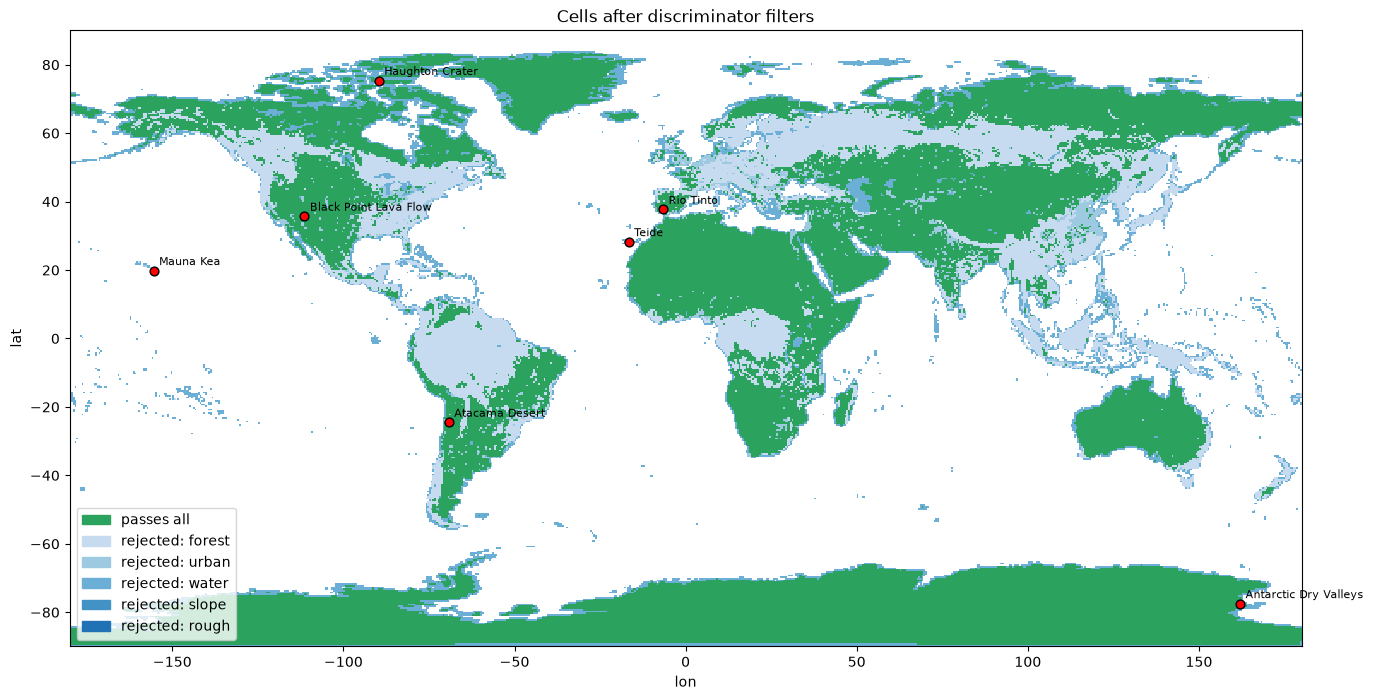

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

NROWS = int(180 / RES)                       # 360

def to_grid(df, values):
    """Put a per-cell value back onto the 360 x 720 grid using cell_id."""
    grid = np.full((NROWS, NCOLS), np.nan)
    rows, cols = np.divmod(df.cell_id.values, NCOLS)
    grid[rows, cols] = values
    return grid

# Category per cell: 0 = passes, 1.. = first filter that rejected it
names = list(FILTERS)
def first_fail(r):
    for i, n in enumerate(names, start=1):
        if not r[f"pass_{n}"]:
            return i
    return 0
cat = cells.apply(first_fail, axis=1).values
grid = to_grid(cells, cat)

colors = ["#2ca25f"] + ["#c6dbef", "#9ecae1", "#6baed6", "#4292c6", "#2171b5"][:len(names)]
fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(grid, extent=[-180, 180, -90, 90], cmap=ListedColormap(colors),
          vmin=0, vmax=len(names), interpolation="nearest")
ax.scatter(analogs.lon, analogs.lat, c="red", s=40, edgecolor="k", zorder=3)
for _, a in analogs.iterrows():
    ax.annotate(a["name"], (a.lon, a.lat), xytext=(4, 4), textcoords="offset points", fontsize=8)

legend = [Patch(color=colors[0], label="passes all")] + \
         [Patch(color=colors[i], label=f"rejected: {n}") for i, n in enumerate(names, start=1)]
ax.legend(handles=legend, loc="lower left")
ax.set_title("Cells after discriminator filters")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()